# Credit Card Fraud Detection

Standard supervised-learning take on the ULB credit card fraud dataset (Dal Pozzolo et al.; the Kaggle `creditcard.csv`, also on OpenML as dataset 1597): 284,807 real card transactions by European cardholders over two days in September 2013, with 28 anonymized PCA features + Amount + Time + Class. Severe class imbalance, only 492 frauds (0.17%). Kaggle needs a login, so I download the same CSV from the public copy TensorFlow uses in its imbalanced-data tutorial.

I'm comparing a class-weighted logistic regression to XGBoost, plus SMOTE oversampling on the LR side as a sanity check.

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_recall_curve, classification_report)

np.random.seed(2024)
DATA = Path('../../data/fraud')
DATA.mkdir(parents=True, exist_ok=True)
CSV = DATA / 'creditcard.csv'

In [2]:
import urllib.request
if not CSV.exists():
    urllib.request.urlretrieve("https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv", CSV)
df = pd.read_csv(CSV)
print('loaded creditcard.csv', df.shape, '| fraud rate', round(df['Class'].mean(), 5))

loaded creditcard.csv (284807, 31) | fraud rate 0.00173


In [3]:
feat_cols = [c for c in df.columns if c != 'Class']
X = df[feat_cols].values
y = df['Class'].values

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
scaler = StandardScaler().fit(X_tr)
X_tr_s = scaler.transform(X_tr)
X_te_s = scaler.transform(X_te)
print('train', X_tr.shape, 'pos', y_tr.sum(), '| test', X_te.shape, 'pos', y_te.sum())

train (213605, 30) pos 369 | test (71202, 30) pos 123


## Class-weighted logistic regression baseline

`class_weight='balanced'` is the lazy way to deal with imbalance and it's usually fine as a first pass. I'm tracking PR-AUC (`average_precision_score`) rather than ROC-AUC because ROC is essentially always near 1.0 on this kind of imbalance and tells you nothing useful.

In [4]:
lr = LogisticRegression(max_iter=2000, class_weight='balanced', solver='lbfgs')
lr.fit(X_tr_s, y_tr)
p_lr = lr.predict_proba(X_te_s)[:, 1]
roc_lr = roc_auc_score(y_te, p_lr)
ap_lr  = average_precision_score(y_te, p_lr)
print(f'LR  ROC-AUC={roc_lr:.4f}  PR-AUC={ap_lr:.4f}')

LR  ROC-AUC=0.9726  PR-AUC=0.7039


In [5]:
# Optional SMOTE branch. imbalanced-learn is in requirements but guard the import
# so the notebook still runs on a clean env.
try:
    from imblearn.over_sampling import SMOTE
    sm = SMOTE(sampling_strategy=0.1, random_state=42, k_neighbors=3)
    Xr, yr = sm.fit_resample(X_tr_s, y_tr)
    lr2 = LogisticRegression(max_iter=2000).fit(Xr, yr)
    p_lr2 = lr2.predict_proba(X_te_s)[:, 1]
    print(f'LR+SMOTE  PR-AUC={average_precision_score(y_te, p_lr2):.4f}')
except ImportError:
    print('imbalanced-learn not installed; skipping SMOTE comparison')

LR+SMOTE  PR-AUC=0.7192


## XGBoost

In [6]:
try:
    from xgboost import XGBClassifier
    spw = float((y_tr == 0).sum()) / max(1, (y_tr == 1).sum())
    xgb = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                        scale_pos_weight=spw, eval_metric='aucpr',
                        tree_method='hist', random_state=42, n_jobs=2)
    xgb.fit(X_tr_s, y_tr)
    p_xgb = xgb.predict_proba(X_te_s)[:, 1]
    print(f'XGB  ROC-AUC={roc_auc_score(y_te, p_xgb):.4f}  '
          f'PR-AUC={average_precision_score(y_te, p_xgb):.4f}')
except ImportError:
    print('xgboost not installed -- skipping')
    p_xgb = None

XGB  ROC-AUC=0.9763  PR-AUC=0.8601


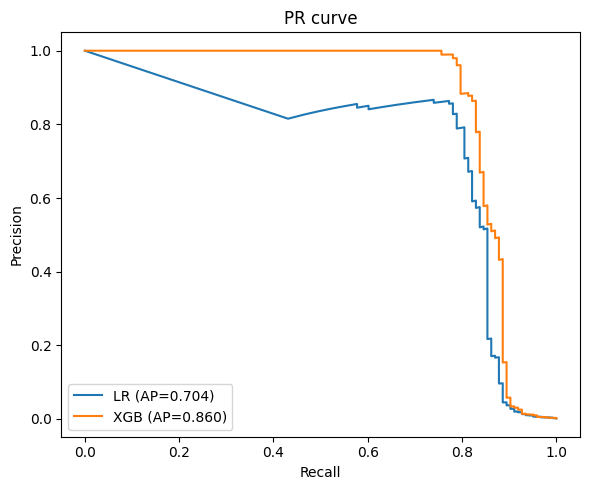

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, p in [('LR', p_lr), ('XGB', p_xgb)]:
    if p is None: continue
    prec, rec, _ = precision_recall_curve(y_te, p)
    ax.plot(rec, prec, label=f'{name} (AP={average_precision_score(y_te, p):.3f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.set_title('PR curve')
ax.legend(); plt.tight_layout(); plt.show()

## Results

On the full 284,807 transactions (71,202 held out, 123 of them fraud), XGBoost gets PR-AUC 0.860 against 0.704 for class-weighted logistic regression; SMOTE barely moves the logistic model (0.719). ROC-AUC is 0.97+ for both, which is exactly why I don't lean on it here. The gap between the models only shows up in PR-AUC.

## What I'd do next

- Pick the threshold by where the PR curve elbows, not by the default 0.5. On real fraud data the operating point is set by how many alerts the analyst team can chase per day, which is a business constraint and not a model one.
- Cost-sensitive eval: a false negative is a missed fraud (expensive); a false positive is a customer call (cheap but annoying). The right metric is total cost on a held-out month.
- Time-based split instead of random. The `Time` column only covers two days here, so the honest version would train on day one and test on day two; on a longer history I'd hold out the most recent weeks, because fraud patterns drift.